# PJM DART Spread — Modeling & Baselines

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.data.data_collection import INPUT_DATA_DIR

train = pd.read_csv(
    INPUT_DATA_DIR / "model_inputs.csv",
    index_col="interval_start_utc",
    parse_dates=True,
)

test = pd.read_csv(
    INPUT_DATA_DIR / "model_inputs_test.csv",
    index_col="interval_start_utc",
    parse_dates=True,
)

In [2]:
from scripts.data.data_collection import HOLDOUT_START
for name, df in [("model_inputs", train), ("model_inputs_test", test)]:
    print(f"{name:20s} {df.index.min()} -> {df.index.max()}  ({len(df)} строк)")
print("HOLDOUT_START:", HOLDOUT_START)
print("intersection:", len(train.index.intersection(test.index)))

model_inputs         2019-01-08 00:00:00+00:00 -> 2025-12-31 23:00:00+00:00  (61200 строк)
model_inputs_test    2026-01-08 00:00:00+00:00 -> 2026-07-31 23:00:00+00:00  (4920 строк)
HOLDOUT_START: 2026-01-01
intersection: 0


In [3]:
from scripts.data.features import mask_iqr_outliers

rt_m = mask_iqr_outliers(train["rt_lmp"])
da_m = mask_iqr_outliers(train["da_lmp"])
keep = rt_m.notna() & da_m.notna()

print(f"train: {len(train)} -> {keep.sum()}")
train = train.loc[keep].copy()

train: 61200 -> 54674


In [4]:
train = train.drop(columns=["rt_lmp", "da_lmp"])
test  = test.drop(columns=["rt_lmp", "da_lmp"])

In [5]:
TARGET = "dart"
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test,  y_test  = test.drop(columns=[TARGET]),  test[TARGET]

assert list(X_train.columns) == list(X_test.columns)
print(X_train.shape, X_test.shape)

(54674, 30) (4920, 30)


In [19]:
num = X_train.select_dtypes("number").columns
shift = ((X_test[num].mean() - X_train[num].mean()) / X_train[num].std()).sort_values(key=abs, ascending=False)
print(shift.head(8))

dart_std_24       1.880617
rt_lmp_lag_48     1.852167
rt_lmp_lag_1      1.391745
rt_lmp_lag_24     1.246641
rt_lmp_lag_168    0.988238
dart_mean_168    -0.701053
dart_mean_24     -0.509681
dart_lag_2       -0.436655
dtype: float64


In [21]:
import pandas as pd, numpy as np

d = df["dart"].dropna()

# 1. shape of the tail
print(d.quantile([0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1]).round(2))

# 2. spike census at candidate thresholds
def census(d, gpos, gneg):
    for name, m in [("INC/pos", d >= gpos), ("DEC/neg", d <= -gneg)]:
        days = d.index[m].normalize().nunique()
        share = d[m].abs().sum() / d.abs().sum()
        print(f"g=({gpos},{gneg}) {name}: {m.sum():5d} hrs  {m.mean():6.2%}  "
              f"{days:4d} distinct days  {share:5.1%} of total |dart|")

for g in [(5, 10), (5, 30), (10, 30), (15, 50)]:
    census(d, *g)

# 3. is the base rate stable across years? (regime death check)
yr = d.groupby(d.index.year)
print(pd.DataFrame({
    "n_hours": yr.size(),
    "pos_rate": yr.apply(lambda s: (s >= 5).mean()),
    "neg_rate": yr.apply(lambda s: (s <= -30).mean()),
    "neg_days": yr.apply(lambda s: s.index[s <= -30].normalize().nunique()),
    "mean": yr.mean(), "p01": yr.quantile(.01), "p99": yr.quantile(.99),
}).round(3))

# 4. do features exist when it matters? (they often go missing exactly on spike hours)
feats = df.drop(columns=["dart"])
spike = (d <= -30) | (d >= 5)
gap = pd.DataFrame({"all": feats.isna().mean(),
                    "spike_hours": feats.loc[spike.reindex(feats.index, fill_value=False)].isna().mean()})
print(gap[gap.max(axis=1) > 0].round(3))

0.000   -1574.12
0.001   -1266.81
0.010    -517.65
0.050    -168.07
0.250      -3.99
0.500       4.57
0.750      16.79
0.950      88.01
0.990     341.15
0.999     775.02
1.000    1075.26
Name: dart, dtype: float64
g=(5,10) INC/pos:  2378 hrs  48.33%   201 distinct days  41.8% of total |dart|
g=(5,10) DEC/neg:  1010 hrs  20.53%   183 distinct days  56.5% of total |dart|
g=(5,30) INC/pos:  2378 hrs  48.33%   201 distinct days  41.8% of total |dart|
g=(5,30) DEC/neg:   705 hrs  14.33%   157 distinct days  54.3% of total |dart|
g=(10,30) INC/pos:  1721 hrs  34.98%   191 distinct days  39.9% of total |dart|
g=(10,30) DEC/neg:   705 hrs  14.33%   157 distinct days  54.3% of total |dart|
g=(15,50) INC/pos:  1332 hrs  27.07%   180 distinct days  38.0% of total |dart|
g=(15,50) DEC/neg:   551 hrs  11.20%   140 distinct days  51.9% of total |dart|
                    n_hours  pos_rate  neg_rate  neg_days  mean      p01  \
interval_start_utc                                                        

## Train

In [6]:
from scripts.models.ridge import run_ridge_backtest

res = run_ridge_backtest(X_train, y_train, X_test, y_test)
res.head()

,actual,ridge
interval_start_utc,,
2026-01-08 00:00:00+00:00,-1.527104,2.743662
2026-01-08 01:00:00+00:00,-1.119073,2.496775
2026-01-08 02:00:00+00:00,2.155167,1.984553
2026-01-08 03:00:00+00:00,0.813980,1.267534
2026-01-08 04:00:00+00:00,1.799220,0.779769


In [8]:
from scripts.models.baselines import run_baseline_backtest

base = run_baseline_backtest(y_train, X_test, y_test)
print(len(res), len(base))
base.head()

4920 4920


,actual,persistence,seasonal_naive
interval_start_utc,,,
2026-01-08 00:00:00+00:00,-1.527104,10.757390,4.540655
2026-01-08 01:00:00+00:00,-1.119073,3.671570,1.671140
2026-01-08 02:00:00+00:00,2.155167,3.574198,1.578914
2026-01-08 03:00:00+00:00,0.813980,3.278015,0.143883
2026-01-08 04:00:00+00:00,1.799220,2.831803,1.477465


In [9]:
common = res.index.intersection(base.index)
backtest_results = pd.concat([
    res.loc[common, ["actual", "ridge"]],
    base.loc[common, ["persistence", "seasonal_naive"]],
], axis=1)
print(len(res), len(base), len(backtest_results))
backtest_results

4920 4920 4920


,actual,ridge,persistence,seasonal_naive
interval_start_utc,,,,
2026-01-08 00:00:00+00:00,-1.527104,2.743662,10.757390,4.540655
2026-01-08 01:00:00+00:00,-1.119073,2.496775,3.671570,1.671140
2026-01-08 02:00:00+00:00,2.155167,1.984553,3.574198,1.578914
2026-01-08 03:00:00+00:00,0.813980,1.267534,3.278015,0.143883
2026-01-08 04:00:00+00:00,1.799220,0.779769,2.831803,1.477465
...,...,...,...,...
2026-07-31 19:00:00+00:00,0.313698,6.654090,17.361540,3.830138
2026-07-31 20:00:00+00:00,-58.753851,7.454754,19.253931,4.142683
2026-07-31 21:00:00+00:00,-34.114863,7.959747,28.127680,4.755283


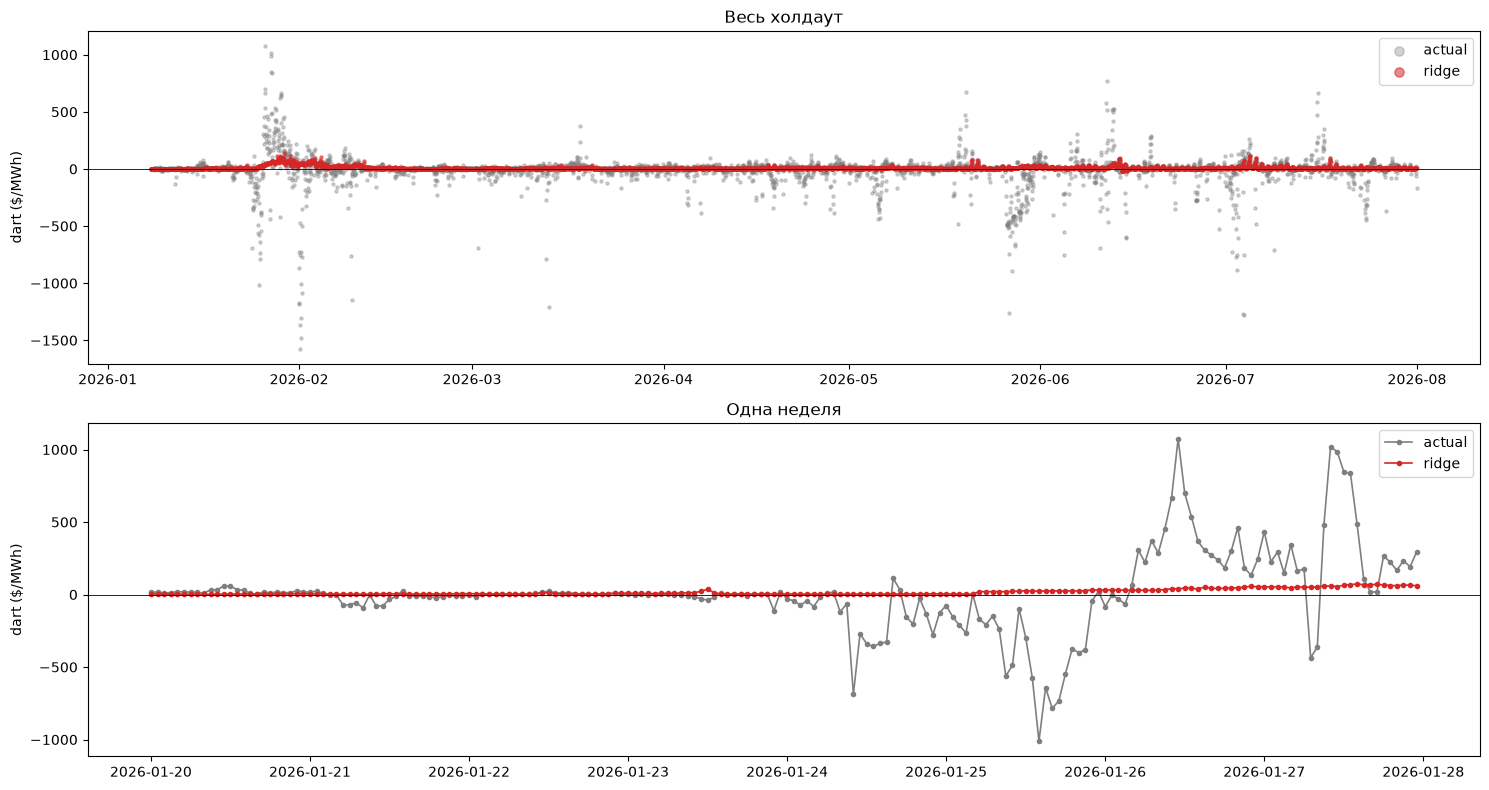

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))

# весь холдаут
ax1.scatter(res.index, res["actual"], s=5, alpha=0.35, color="tab:gray", label="actual")
ax1.scatter(res.index, res["ridge"], s=5, alpha=0.55, color="tab:red", label="ridge")
ax1.axhline(0, color="black", linewidth=0.6)
ax1.set_ylabel("dart ($/MWh)")
ax1.set_title("Весь холдаут")
ax1.legend(markerscale=3)

# одна неделя крупным планом
week = res.loc["2026-01-20":"2026-01-27"]
ax2.plot(week.index, week["actual"], color="tab:gray", linewidth=1.2, marker="o", markersize=3, label="actual")
ax2.plot(week.index, week["ridge"], color="tab:red", linewidth=1.2, marker="o", markersize=3, label="ridge")
ax2.axhline(0, color="black", linewidth=0.6)
ax2.set_ylabel("dart ($/MWh)")
ax2.set_title("Одна неделя")
ax2.legend()

plt.tight_layout()
plt.show()

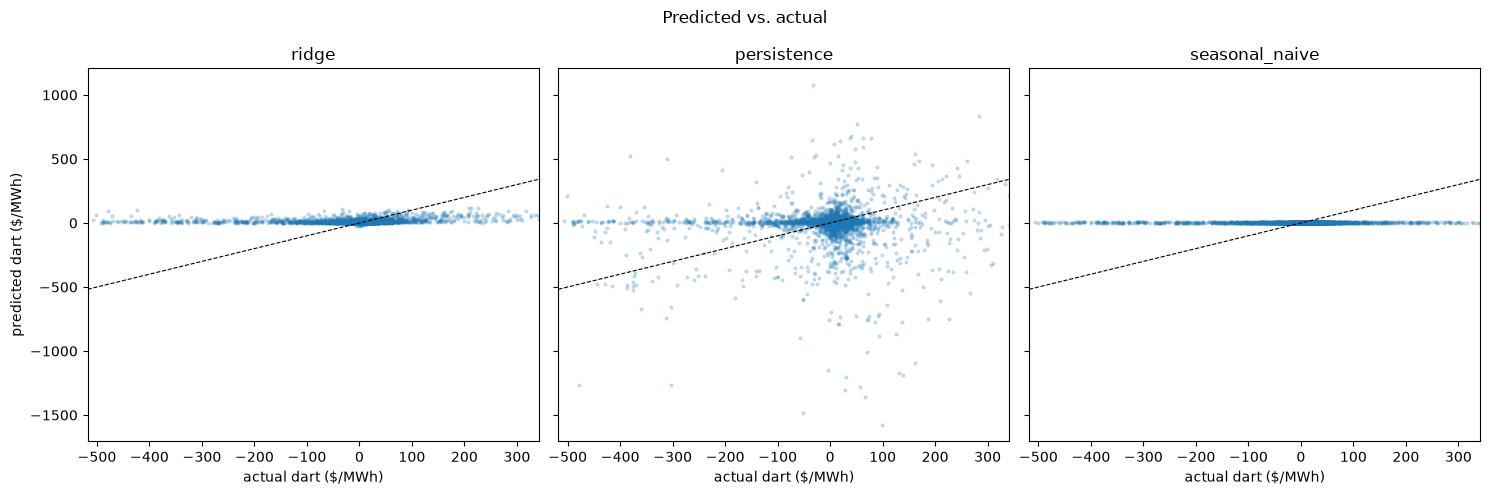

In [10]:
lo, hi = backtest_results["actual"].quantile([0.01, 0.99])
plo, phi = backtest_results[["ridge", "persistence", "seasonal_naive"]].quantile([0.01, 0.99]).values.ravel()[[0, -1]]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, col in zip(axes, ["ridge", "persistence", "seasonal_naive"]):
    ax.scatter(backtest_results["actual"], backtest_results[col], s=4, alpha=0.2)
    ax.axline((lo, lo), (hi, hi), color="black", linewidth=0.8, linestyle="--")
    ax.set_xlim(lo, hi)
    ax.set_xlabel("actual dart ($/MWh)")
    ax.set_title(col)
axes[0].set_ylabel("predicted dart ($/MWh)")
plt.suptitle("Predicted vs. actual")
plt.tight_layout()
plt.show()

In [20]:
print(X_train["rt_lmp_lag_48"].describe())
print(X_test["rt_lmp_lag_48"].describe())
print("test выше train-максимума:", (X_test["rt_lmp_lag_48"] > X_train["rt_lmp_lag_48"].max()).mean())

count    54674.000000
mean        37.214566
std         34.797476
min        -53.570167
25%         20.563565
50%         27.593089
75%         41.880815
max        874.209103
Name: rt_lmp_lag_48, dtype: float64
count    4920.000000
mean      101.665312
std       184.329168
min         3.202591
25%        27.972881
50%        38.737876
75%        79.414784
max      2122.252584
Name: rt_lmp_lag_48, dtype: float64
test выше train-максимума: 0.011585365853658536
